In [1]:
from helper_files.maoa_plate_loader import *
from helper_files.mea_feats_analysis import *
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns



In [2]:


root_dir = "/Users/blancamartin/Downloads/Sandra_MAOA_MEA/"  # adjust as needed
big_df = summarize_all_spike_files(root_dir, show_progress=True)





Recording date folders:   0%|          | 0/29 [00:00<?, ?it/s]

Processing 04.14.2025 / MAOA2 (1 files)
Processing 04.14.2025 / MAOA3 (1 files)
Processing 04.14.2025 / MAOA1 (1 files)
Processing 04.18.2025 / MAOA2 (1 files)
Processing 04.18.2025 / MAOA3 (1 files)
Processing 04.18.2025 / MAOA1 (1 files)
Processing 04.21.2025 / MAOA2 (1 files)
Processing 04.21.2025 / MAOA3 (1 files)
Processing 04.21.2025 / MAOA1 (1 files)
Processing 04.25.2025 / MAOA2 (1 files)
Processing 04.25.2025 / MAOA3 (1 files)
Processing 04.25.2025 / MAOA1 (1 files)
Processing 05.02.2025 / MAOA2 (1 files)
Processing 05.02.2025 / MAOA3 (1 files)
Processing 05.02.2025 / MAOA1 (1 files)
Processing 05.09.2025 / MAOA2 (1 files)
Processing 05.09.2025 / MAOA3 (1 files)
Processing 05.09.2025 / MAOA1 (1 files)
Processing 05.16.2025 / MAOA2 (1 files)
Processing 05.16.2025 / MAOA3 (1 files)
Processing 05.16.2025 / MAOA1 (1 files)
Processing 05.30.2025 / MAOA2 (1 files)
Processing 05.30.2025 / MAOA3 (1 files)
Processing 05.30.2025 / MAOA1 (1 files)
Processing 06.13.2025 / MAOA2 (1 files)


In [3]:
#add experiment group
big_df["experiment"] = big_df.apply(
    lambda row: assign_experiment(row["plate_name"], row["recording_date"]),
    axis=1
)

In [11]:
import numpy as np
import pandas as pd
from itertools import combinations
import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=FutureWarning)

import statsmodels.formula.api as smf
from statsmodels.stats.anova import anova_lm
from scipy.stats import ttest_ind


def _format_p(p, ndigits=6):
    """Format p-values as decimals with fixed number of digits."""
    if p is None or np.isnan(p):
        return ""
    return f"{p:.{ndigits}f}"


def _clean_anova_table(anova):
    """Rename columns, add p-formatted column."""
    cleaned = anova.rename(
        columns={
            "sum_sq": "SS",
            "df": "DF",
            "F": "F_statistic",
            "PR(>F)": "p_value"
        }
    )
    cleaned["p_formatted"] = cleaned["p_value"].apply(_format_p)
    return cleaned


def run_feature_stats(df, feature, threshold_spikes_per_min=5):
    """
    Runs TWO-WAY ANOVA (cell_line × date) and ONE-WAY ANOVA (cell_line)
    + post-hoc t-tests. Handles well-level + electrode-level (for firing/burst).
    P-values formatted. Electrode threshold applies to firing only.
    """

    df = df.copy()
    feature = feature.lower()
    threshold_hz = threshold_spikes_per_min / 60.0

    valid = ["firing", "burst", "network", "synchrony"]
    if feature not in valid:
        raise ValueError(f"feature must be one of {valid}")

    # ---- WELL-LEVEL VALUE EXTRACTION ----
    if feature == "firing":
        df["well_value"] = df["firing_rate_stats_hz"].str[0]
    elif feature == "burst":
        df["well_value"] = df["burst_rate_stats_hz"].str[0]
    elif feature == "network":
        df["well_value"] = df["network_event_rate_hz"]
    elif feature == "synchrony":
        df["well_value"] = df["synchrony_index"]

    df["date_label"] = df["recording_date"].astype(str)

    results = {}

    # ================= LOOP OVER EXPERIMENTS =================
    for exp in sorted(df["experiment"].unique()):
        sub = df[df["experiment"] == exp].dropna(subset=["well_value", "cell_line"]).copy()
        exp_result = {"well": {}, "electrode": {}}

        # ======================================================
        # WELL-LEVEL — TWO-WAY ANOVA
        # ======================================================
        if len(sub["cell_line"].unique()) > 1 and len(sub["date_label"].unique()) > 1:
            model = smf.ols("well_value ~ C(cell_line) * C(date_label)", data=sub).fit()
            anova_tw = anova_lm(model, typ=2)
            exp_result["well"]["two_way_anova"] = _clean_anova_table(anova_tw)
        else:
            exp_result["well"]["two_way_anova"] = None

        # ======================================================
        # WELL-LEVEL — ONE-WAY ANOVA
        # ======================================================
        if len(sub["cell_line"].unique()) > 1:
            model = smf.ols("well_value ~ C(cell_line)", data=sub).fit()
            anova_ow = anova_lm(model, typ=2)
            exp_result["well"]["one_way_anova"] = _clean_anova_table(anova_ow)
        else:
            exp_result["well"]["one_way_anova"] = None

        # ======================================================
        # WELL-LEVEL — POST-HOC t-tests
        # ======================================================
        posthoc_rows = []
        lines = sorted(sub["cell_line"].unique())
        pairs = list(combinations(lines, 2))
        m = len(pairs)

        for a, b in pairs:
            xa = sub.loc[sub["cell_line"] == a, "well_value"].dropna().values
            xb = sub.loc[sub["cell_line"] == b, "well_value"].dropna().values
            if len(xa) < 2 or len(xb) < 2:
                continue
            t, p = ttest_ind(xa, xb, equal_var=False)
            p_adj = min(p * m, 1.0)
            posthoc_rows.append({
                "group1": a,
                "group2": b,
                "mean1": float(np.mean(xa)),
                "mean2": float(np.mean(xb)),
                "difference": float(np.mean(xa) - np.mean(xb)),
                "t_statistic": float(t),
                "p_raw": float(p),
                "p_raw_fmt": _format_p(p),
                "p_bonf": float(p_adj),
                "p_bonf_fmt": _format_p(p_adj),
            })

        exp_result["well"]["posthoc"] = pd.DataFrame(posthoc_rows) if posthoc_rows else None

        # ======================================================
        # ELECTRODE LEVEL (FIRING + BURST ONLY)
        # ======================================================
        if feature in ["firing", "burst"]:
            key = "firing_rate_vector_hz" if feature == "firing" else "burst_rate_vector_hz"

            def expand(row):
                return pd.DataFrame({
                    "cell_line": row["cell_line"],
                    "date_label": str(row["recording_date"]),
                    "value": row[key]
                })

            elec_df = pd.concat([expand(r) for _, r in sub.iterrows()], ignore_index=True)
            elec_df = elec_df.dropna(subset=["value"])

            # threshold only for FIRING
            if feature == "firing":
                elec_df = elec_df[elec_df["value"] >= threshold_hz]

            if len(elec_df) == 0 or len(elec_df["cell_line"].unique()) < 2:
                exp_result["electrode"] = {
                    "two_way_anova": None,
                    "one_way_anova": None,
                    "posthoc": None
                }
            else:
                # TWO-WAY ANOVA
                if len(elec_df["date_label"].unique()) > 1:
                    model = smf.ols("value ~ C(cell_line) * C(date_label)", data=elec_df).fit()
                    anova_tw = anova_lm(model, typ=2)
                    exp_result["electrode"]["two_way_anova"] = _clean_anova_table(anova_tw)
                else:
                    exp_result["electrode"]["two_way_anova"] = None

                # ONE-WAY ANOVA
                model = smf.ols("value ~ C(cell_line)", data=elec_df).fit()
                anova_ow = anova_lm(model, typ=2)
                exp_result["electrode"]["one_way_anova"] = _clean_anova_table(anova_ow)

                # POST-HOC
                lines_e = sorted(elec_df["cell_line"].unique())
                pairs_e = list(combinations(lines_e, 2))
                m_e = len(pairs_e)

                post_e = []
                for a, b in pairs_e:
                    xa = elec_df.loc[elec_df["cell_line"] == a, "value"].values
                    xb = elec_df.loc[elec_df["cell_line"] == b, "value"].values
                    if len(xa) < 2 or len(xb) < 2:
                        continue
                    t, p = ttest_ind(xa, xb, equal_var=False)
                    p_adj = min(p * m_e, 1.0)
                    post_e.append({
                        "group1": a,
                        "group2": b,
                        "mean1": float(np.mean(xa)),
                        "mean2": float(np.mean(xb)),
                        "difference": float(np.mean(xa) - np.mean(xb)),
                        "t_statistic": float(t),
                        "p_raw": float(p),
                        "p_raw_fmt": _format_p(p),
                        "p_bonf": float(p_adj),
                        "p_bonf_fmt": _format_p(p_adj),
                    })

                exp_result["electrode"]["posthoc"] = pd.DataFrame(post_e) if post_e else None

        results[exp] = exp_result

    return results


### Exp 3 analysis 

In [4]:
df3 = big_df[big_df["experiment"] == "Exp3"].copy()

df3["firing_mean_hz"] = df3["firing_rate_stats_hz"].str[0]
df3["firing_std_hz"]  = df3["firing_rate_stats_hz"].str[1]
df3["plate_well"] = df3["plate_name"] + "_" + df3["well"]




#### Firing rate


=== Plotting Experiment Exp3 ===


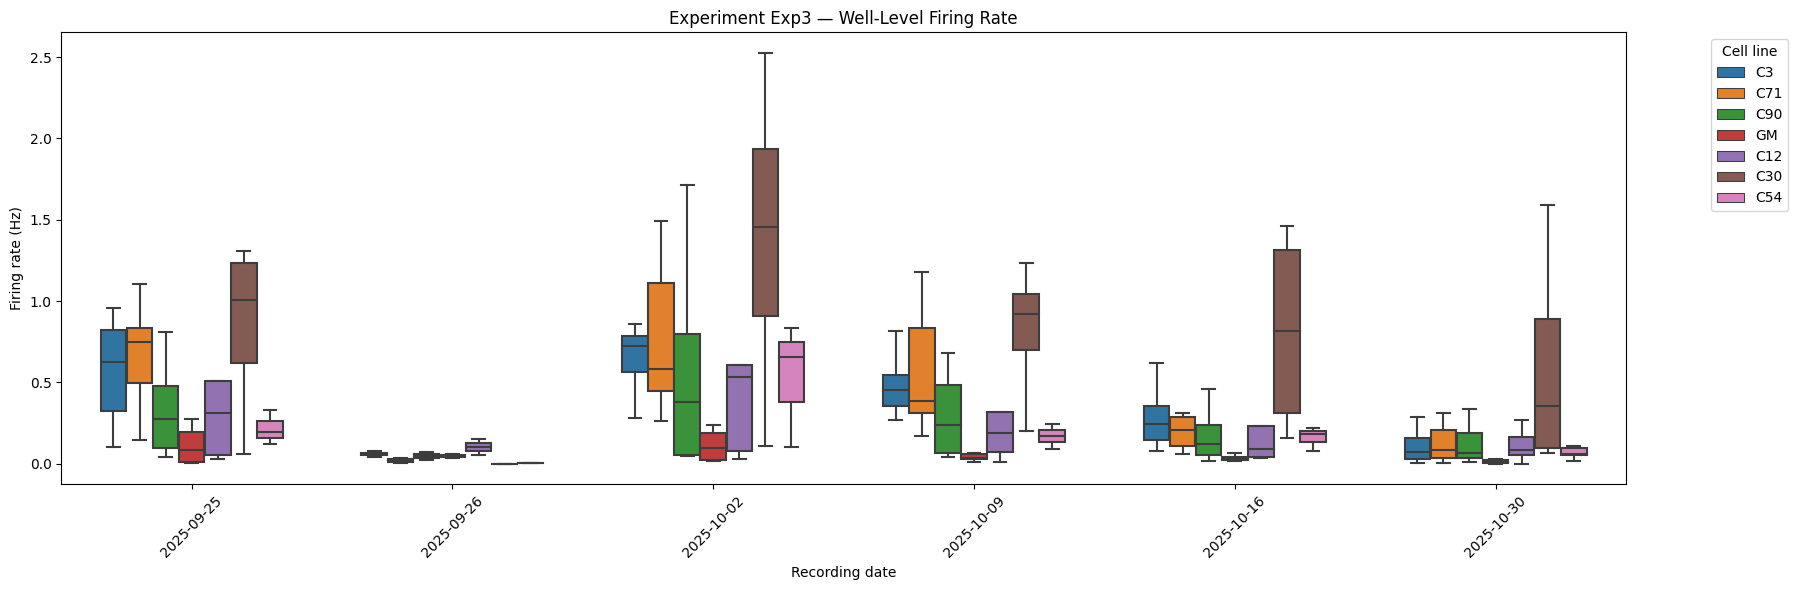

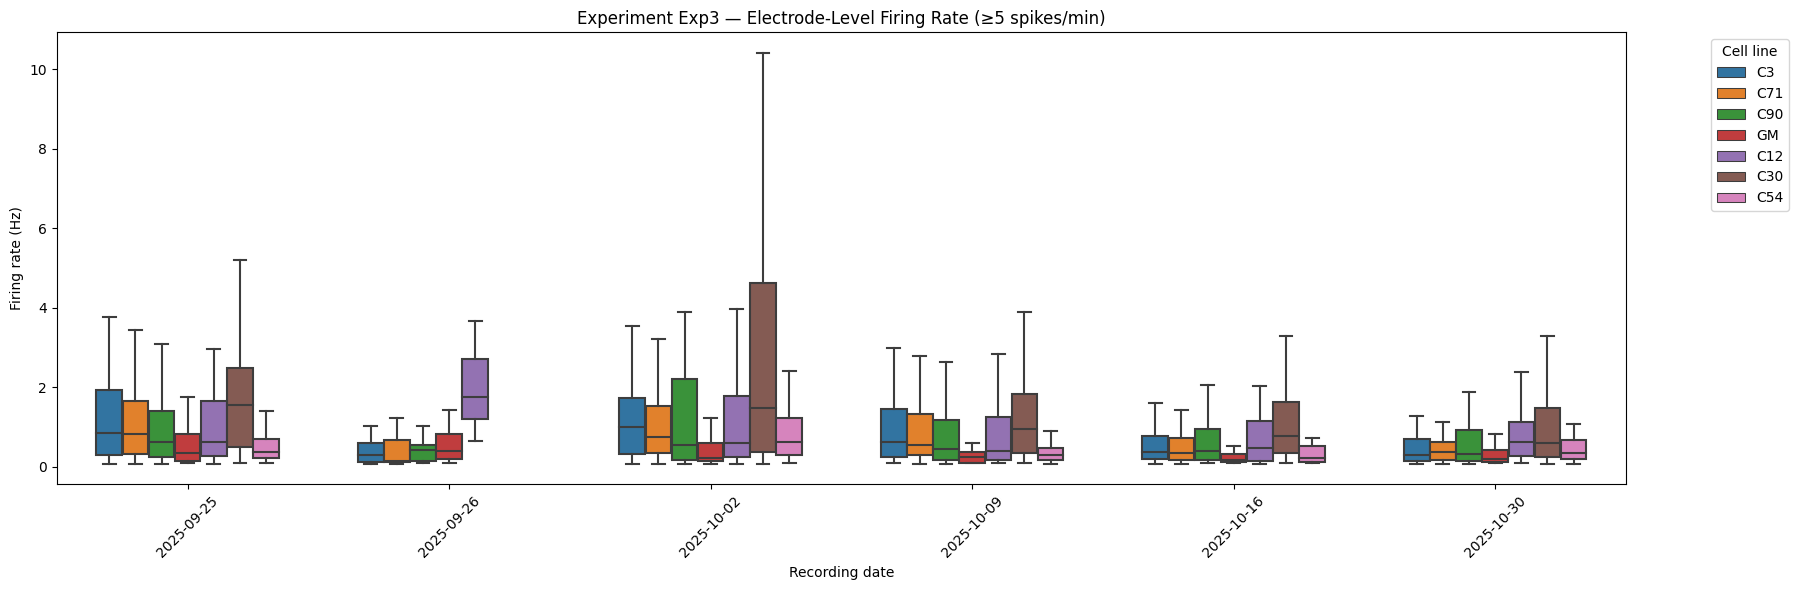

In [5]:
plot_feature_boxplots(df3, "firing")


In [15]:
firing_stats = run_feature_stats(big_df, "firing")


In [13]:
firing_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),8.945240,6.0,12.384069,1.020758e-11,0.000000
C(date_label),7.092670,5.0,11.783176,6.567789e-10,0.000000
C(cell_line):C(date_label),2.073537,30.0,0.574134,9.633882e-01,0.963388
Residual,22.391867,186.0,NaN,NaN,


In [17]:
firing_stats["Exp3"]["electrode"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),317.612399,6.0,15.222406,2.521617e-12,0.000000
C(date_label),414.676597,5.0,23.849355,3.014536e-15,0.000000
C(cell_line):C(date_label),97.491143,30.0,0.934504,5.639556e-01,0.563956
Residual,10248.092066,2947.0,NaN,NaN,


In [14]:
firing_stats["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),525.105444,6.0,24.61015,1.291225e-28,0.000000
Residual,10597.349754,2980.0,NaN,NaN,


In [18]:
firing_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),9.031696,6.0,10.541438,2.760410e-10,0.000000
Residual,31.558073,221.0,NaN,NaN,


In [19]:
firing_stats["Exp3"]["electrode"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_statistic,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,1.356973,1.103899,0.253075,2.159375,3.124982e-02,0.031250,6.562463e-01,0.656246
1,C12,C30,1.356973,2.064496,-0.707522,-4.078898,4.949005e-05,0.000049,1.039291e-03,0.001039
2,C12,C54,1.356973,0.699149,0.657824,5.081735,5.000246e-07,0.000001,1.050052e-05,0.000011
3,C12,C71,1.356973,1.099313,0.257660,2.195264,2.855514e-02,0.028555,5.996580e-01,0.599658
4,C12,C90,1.356973,1.098662,0.258311,1.929269,5.409710e-02,0.054097,1.000000e+00,1.000000
5,C12,GM,1.356973,0.546356,0.810617,6.386533,3.961490e-10,0.000000,8.319129e-09,0.000000
6,C3,C30,1.103899,2.064496,-0.960597,-6.439799,2.301686e-10,0.000000,4.833540e-09,0.000000
7,C3,C54,1.103899,0.699149,0.404749,4.285693,2.174296e-05,0.000022,4.566021e-04,0.000457
8,C3,C71,1.103899,1.099313,0.004585,0.059502,9.525614e-01,0.952561,1.000000e+00,1.000000
9,C3,C90,1.103899,1.098662,0.005236,0.052132,9.584379e-01,0.958438,1.000000e+00,1.000000


In [21]:
firing_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_statistic,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.322104,0.369581,-0.047478,-0.499638,6.194000e-01,0.619400,1.000000,1.000000
1,C12,C30,0.322104,0.794180,-0.472076,-3.042761,4.090054e-03,0.004090,0.085891,0.085891
2,C12,C54,0.322104,0.200961,0.121142,1.281561,2.062681e-01,0.206268,1.000000,1.000000
3,C12,C71,0.322104,0.403572,-0.081468,-0.792122,4.313273e-01,0.431327,1.000000,1.000000
4,C12,C90,0.322104,0.251950,0.070154,0.717072,4.762837e-01,0.476284,1.000000,1.000000
5,C12,GM,0.322104,0.057095,0.265009,3.250339,2.696903e-03,0.002697,0.056635,0.056635
6,C3,C30,0.369581,0.794180,-0.424598,-2.997032,5.332908e-03,0.005333,0.111991,0.111991
7,C3,C54,0.369581,0.200961,0.168620,2.400080,2.023070e-02,0.020231,0.424845,0.424845
8,C3,C71,0.369581,0.403572,-0.033990,-0.419084,6.764361e-01,0.676436,1.000000,1.000000
9,C3,C90,0.369581,0.251950,0.117632,1.575864,1.193633e-01,0.119363,1.000000,1.000000


#### Bursting rate


=== Plotting Experiment Exp3 ===


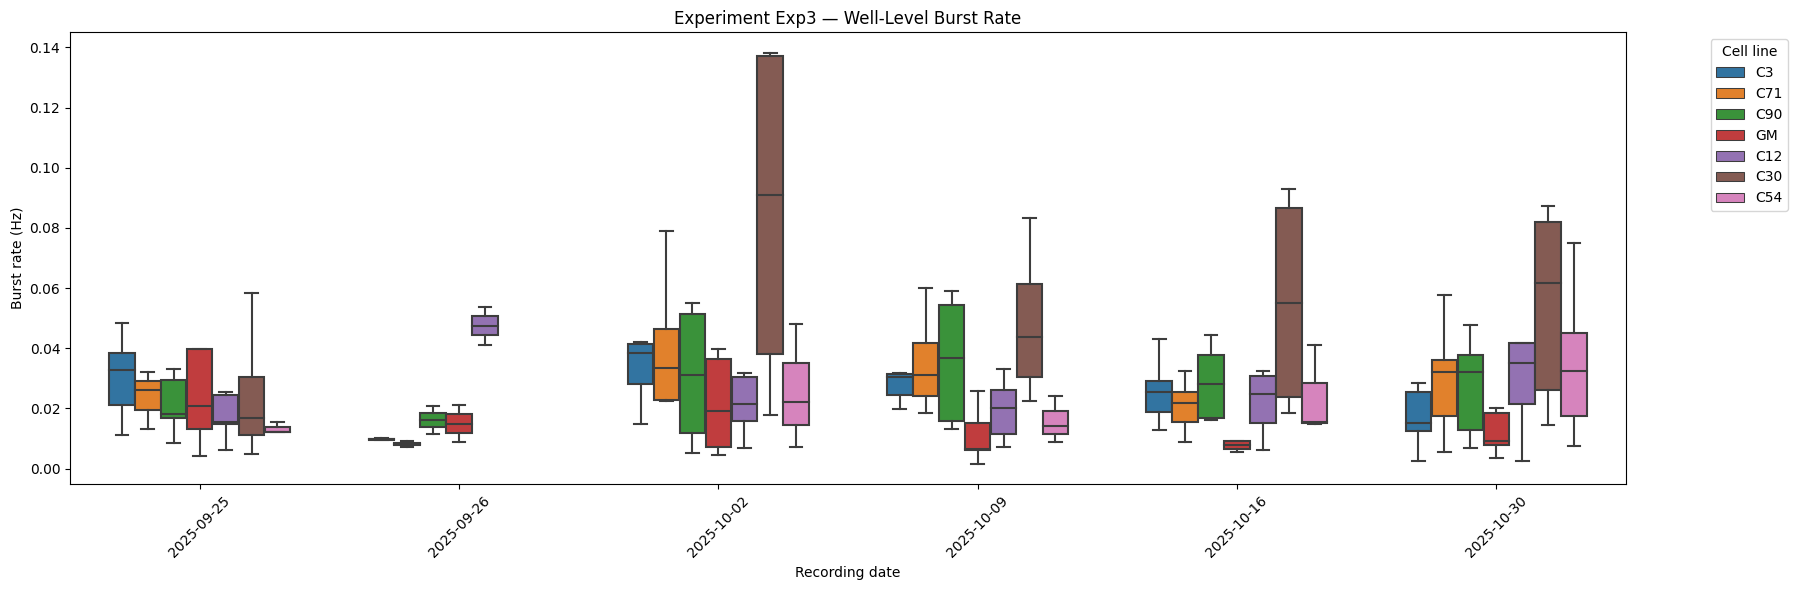

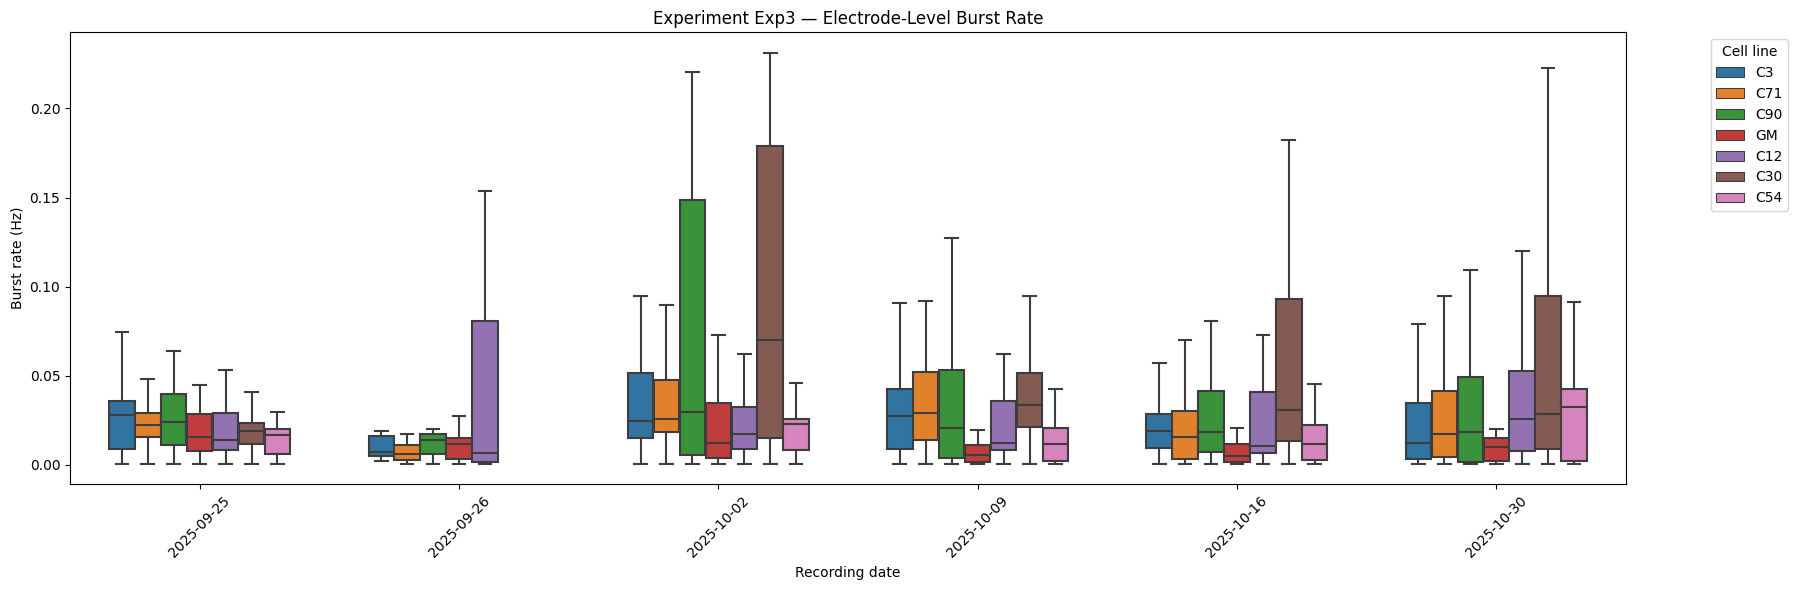

In [6]:
plot_feature_boxplots(df3, "burst")

In [22]:
bursting_stats = run_feature_stats(big_df, "burst")

In [23]:
bursting_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.024629,6.0,8.678498,0.000002,0.000002
C(date_label),0.004674,5.0,1.976307,0.119306,0.119306
C(cell_line):C(date_label),0.014659,30.0,1.033073,0.427569,0.427569
Residual,0.082299,174.0,NaN,NaN,


In [24]:
bursting_stats["Exp3"]["electrode"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.675217,6.0,62.785572,4.352168e-51,0.000000
C(date_label),0.235556,5.0,26.284055,8.767530e-17,0.000000
C(cell_line):C(date_label),0.254224,30.0,4.727849,4.081662e-15,0.000000
Residual,5.533104,3087.0,NaN,NaN,


In [25]:
bursting_stats["Exp3"]["electrode"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.519696,6.0,45.515398,1.136938e-53,0.000000
Residual,5.937376,3120.0,NaN,NaN,


In [26]:
bursting_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.019734,6.0,6.748665,0.000002,0.000002
Residual,0.100885,207.0,NaN,NaN,


In [28]:
bursting_stats["Exp3"]["electrode"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_statistic,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.024687,0.031018,-0.006331,-2.951031,3.237066e-03,0.003237,6.797838e-02,0.067978
1,C12,C30,0.024687,0.059887,-0.035200,-10.470533,8.230410e-24,0.000000,1.728386e-22,0.000000
2,C12,C54,0.024687,0.018392,0.006295,3.399508,7.137180e-04,0.000714,1.498808e-02,0.014988
3,C12,C71,0.024687,0.031392,-0.006705,-3.645602,2.807807e-04,0.000281,5.896395e-03,0.005896
4,C12,C90,0.024687,0.041243,-0.016556,-5.341895,1.351485e-07,0.000000,2.838118e-06,0.000003
5,C12,GM,0.024687,0.015618,0.009068,4.308546,2.075405e-05,0.000021,4.358351e-04,0.000436
6,C3,C30,0.031018,0.059887,-0.028868,-8.219637,8.816758e-16,0.000000,1.851519e-14,0.000000
7,C3,C54,0.031018,0.018392,0.012626,5.976859,3.202057e-09,0.000000,6.724320e-08,0.000000
8,C3,C71,0.031018,0.031392,-0.000374,-0.177913,8.588200e-01,0.858820,1.000000e+00,1.000000
9,C3,C90,0.031018,0.041243,-0.010225,-3.134771,1.796613e-03,0.001797,3.772886e-02,0.037729


In [27]:
bursting_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_statistic,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.026807,0.027669,-0.000862,-0.187965,0.851520,0.851520,1.000000,1.000000
1,C12,C30,0.026807,0.053857,-0.027050,-3.140913,0.003607,0.003607,0.075741,0.075741
2,C12,C54,0.026807,0.024718,0.002089,0.375475,0.709419,0.709419,1.000000,1.000000
3,C12,C71,0.026807,0.029917,-0.003110,-0.652084,0.516679,0.516679,1.000000,1.000000
4,C12,C90,0.026807,0.029571,-0.002764,-0.561910,0.576103,0.576103,1.000000,1.000000
5,C12,GM,0.026807,0.016943,0.009863,2.117530,0.038498,0.038498,0.808463,0.808463
6,C3,C30,0.027669,0.053857,-0.026188,-3.116323,0.004051,0.004051,0.085063,0.085063
7,C3,C54,0.027669,0.024718,0.002951,0.563892,0.576612,0.576612,1.000000,1.000000
8,C3,C71,0.027669,0.029917,-0.002248,-0.513026,0.609516,0.609516,1.000000,1.000000
9,C3,C90,0.027669,0.029571,-0.001902,-0.418532,0.676833,0.676833,1.000000,1.000000


#### Network event rate


=== Plotting Experiment Exp3 ===


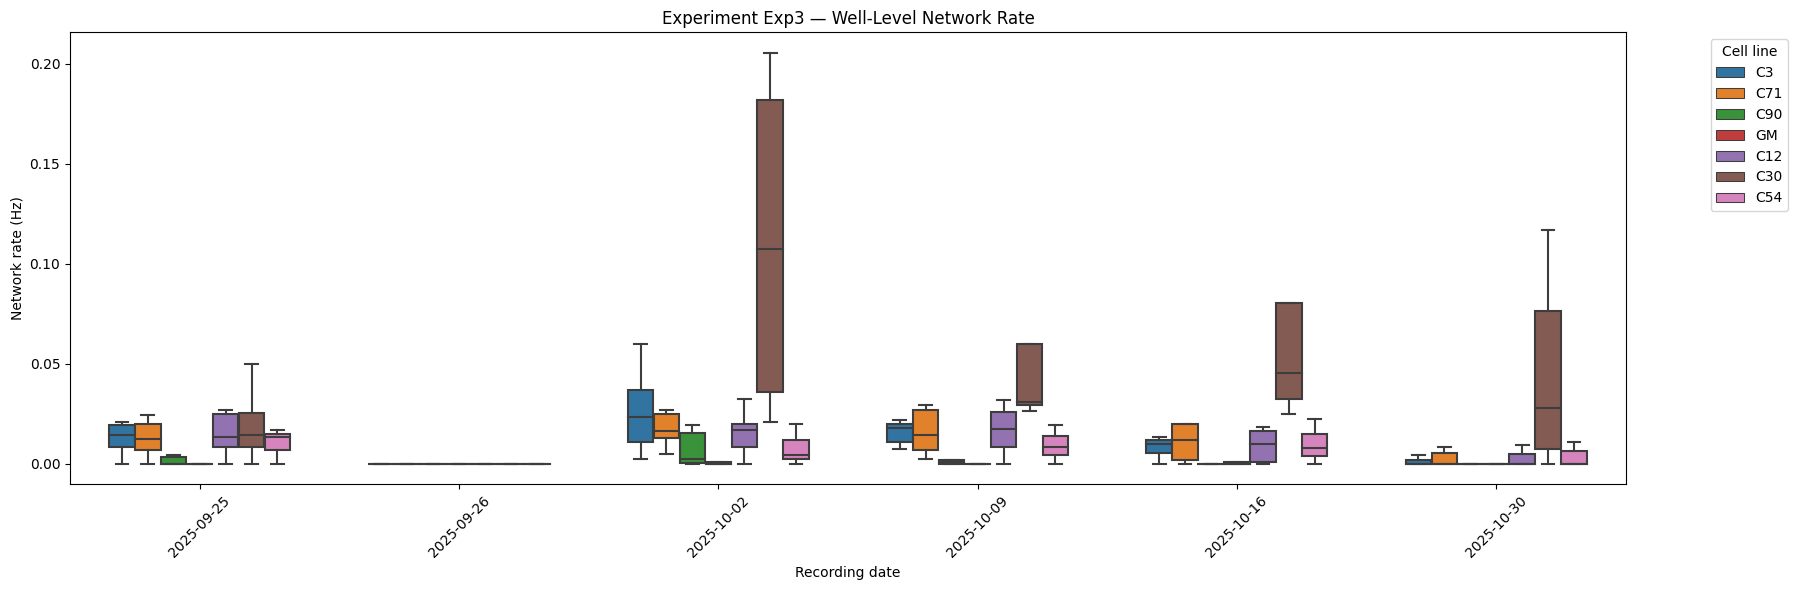

In [7]:
plot_feature_boxplots(df3, "network")

In [29]:
network_stats = run_feature_stats(big_df, "network")

In [30]:
network_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.047374,6.0,9.120220,9.513196e-09,0.000000
C(date_label),0.017659,5.0,4.079564,1.544390e-03,0.001544
C(cell_line):C(date_label),0.017452,30.0,0.671952,9.014819e-01,0.901482
Residual,0.161025,186.0,NaN,NaN,


In [31]:
network_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.047820,6.0,8.980422,8.780115e-09,0.000000
Residual,0.196136,221.0,NaN,NaN,


In [32]:
network_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_statistic,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.009941,0.011952,-0.002011,-0.679902,0.498888,0.498888,1.000000,1.000000
1,C12,C30,0.009941,0.054628,-0.044687,-3.738019,0.000955,0.000955,0.020060,0.020060
2,C12,C54,0.009941,0.006867,0.003074,1.160612,0.251718,0.251718,1.000000,1.000000
3,C12,C71,0.009941,0.016160,-0.006219,-1.400165,0.167342,0.167342,1.000000,1.000000
4,C12,C90,0.009941,0.015689,-0.005748,-0.761221,0.450776,0.450776,1.000000,1.000000
5,C12,GM,0.009941,0.002273,0.007668,3.171844,0.002374,0.002374,0.049856,0.049856
6,C3,C30,0.011952,0.054628,-0.042676,-3.552247,0.001500,0.001500,0.031490,0.031490
7,C3,C54,0.011952,0.006867,0.005085,1.750790,0.085683,0.085683,1.000000,1.000000
8,C3,C71,0.011952,0.016160,-0.004208,-0.915135,0.363891,0.363891,1.000000,1.000000
9,C3,C90,0.011952,0.015689,-0.003737,-0.488891,0.627348,0.627348,1.000000,1.000000


#### Synchrony


=== Plotting Experiment Exp3 ===


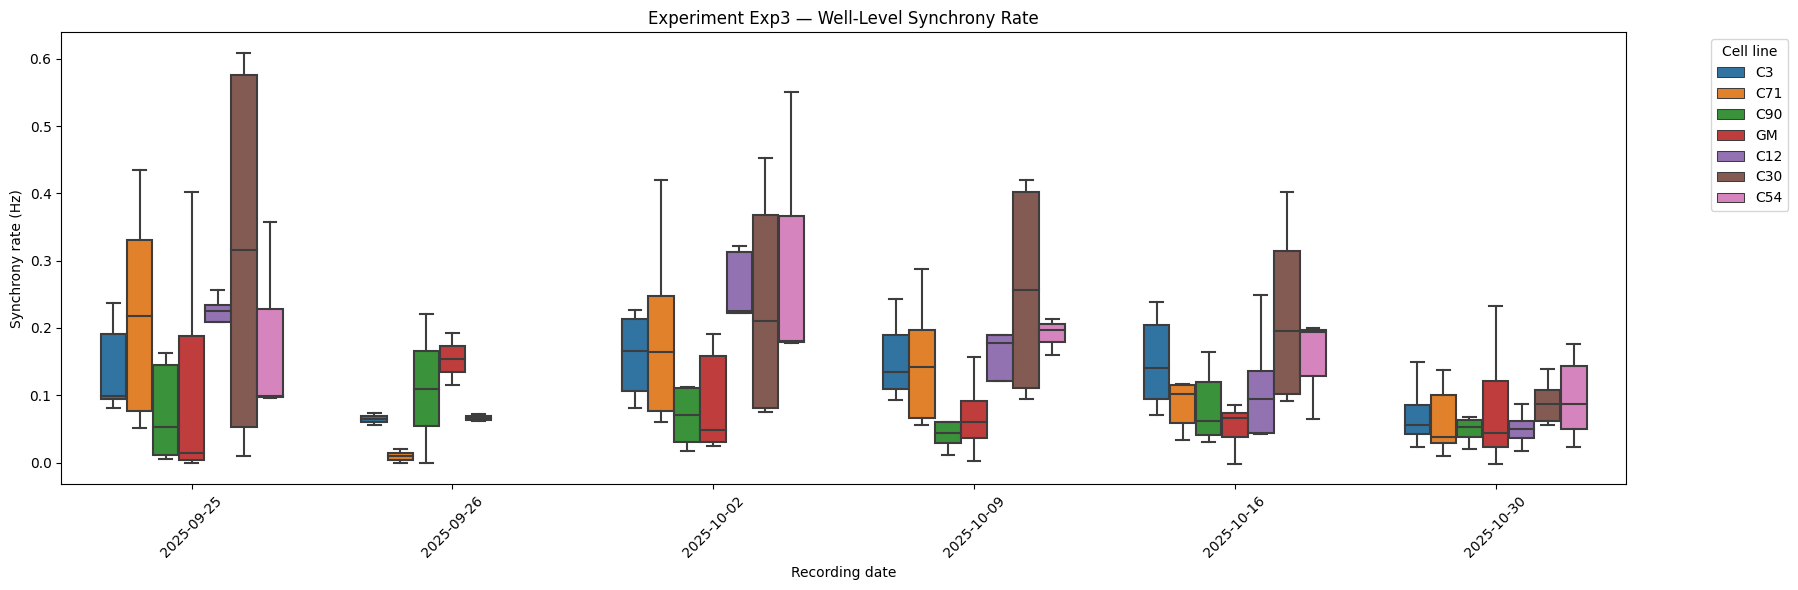

In [8]:
plot_feature_boxplots(df3, "synchrony")

In [39]:
synchrony_stats = run_feature_stats(big_df, "synchrony")

In [34]:
synchrony_stats["Exp3"]["well"]["two_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.418215,6.0,6.343891,8.425681e-05,0.000084
C(date_label),0.659928,5.0,12.012508,3.269572e-07,0.000000
C(cell_line):C(date_label),0.249857,30.0,0.758016,8.048762e-01,0.804876
Residual,1.999698,182.0,NaN,NaN,


In [36]:
synchrony_stats["Exp3"]["well"]["one_way_anova"]

,SS,DF,F_statistic,p_value,p_formatted
C(cell_line),0.285558,6.0,3.830122,0.001194,0.001194
Residual,2.671582,215.0,NaN,NaN,


In [37]:
synchrony_stats["Exp3"]["well"]["posthoc"]

,group1,group2,mean1,mean2,difference,t_statistic,p_raw,p_raw_fmt,p_bonf,p_bonf_fmt
0,C12,C3,0.133816,0.119967,0.013849,0.649221,0.519166,0.519166,1.000000,1.000000
1,C12,C30,0.133816,0.201342,-0.067526,-1.644984,0.109124,0.109124,1.000000,1.000000
2,C12,C54,0.133816,0.170157,-0.036341,-1.057546,0.298577,0.298577,1.000000,1.000000
3,C12,C71,0.133816,0.122957,0.010859,0.413884,0.680307,0.680307,1.000000,1.000000
4,C12,C90,0.133816,0.086629,0.047187,1.921513,0.059127,0.059127,1.000000,1.000000
5,C12,GM,0.133816,0.087884,0.045933,1.863899,0.067005,0.067005,1.000000,1.000000
6,C3,C30,0.119967,0.201342,-0.081375,-2.123301,0.043000,0.043000,0.902997,0.902997
7,C3,C54,0.119967,0.170157,-0.050190,-1.616032,0.120377,0.120377,1.000000,1.000000
8,C3,C71,0.119967,0.122957,-0.002990,-0.137593,0.891038,0.891038,1.000000,1.000000
9,C3,C90,0.119967,0.086629,0.033338,1.695165,0.094864,0.094864,1.000000,1.000000
